In [131]:
from __future__ import annotations

import time
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from typing import List, Dict, Tuple, Optional

# Online Causal Forest

The Online Causal Forest training algorithm is the following:

1. We receive a new datapoint $W_i = (Y_i, D_i, X_i)$
2. The Forest consumes this point and updates summaries and/or splits leafs

## How Forest looks like
The forest consists of $B$ trees $T_b$. Each datapoint is passed to every tree in a forest. The CATE $\tau(x)$ is an average of computed CATEs of each forest:
$$ \tau(x) = \frac{1}{B}\sum_{b=1}^B \tau_b(x). $$

## How each tree splits

Each tree pushes a new observation down to a leaf according to the splits the tree have already made. Every observation becomes either a part of an estimation stream or a structural stream. If its a part of estimation stream, then this observation is used for computation of ATE, otherwise it is used to determine the next split.

Whenever a new leaf is created, we draw a number $m = max(Poisson(\theta) + 1, max_features)$, and then take random $m$ features ${i}$ at which candidate splits will be considered. Then, we create a grid ${c_j}_{j=1}^J$ of a support of each chosen feature. For each pair (i, c) we keep track of summaries $(n_0, n_1, Y_0, Y_1)$, where $n_d$ is a number of observations in a group $d$ and $Y_d$ is a sum of outcomes in a group $d$. In order to determine a split, we wait until the leaf observes at least $n_{struct}$ structural observations and then we split at the $(i, c)$ which yields the maximum heterogeneity between two groups:
$$ (i, c)^* = \text{argmax}_{s = (i, c)} w_L(s)w_R(s)(\tau_L(s) - \tau_R(s))^2, $$
where $w_L(s) = \frac{n_L(s)}{n(s)}$, $n_L(s)$ is the number of observations in a left child, $n_(s)$ is a total number of observations, and $\tau_L(s)$ is an ATE of the left child.

Each leaf's ATE is computed simply as:
$$ \tau(x) = ATE_{current},   $$
where the ATE is using observations from when the split was being decided (from estimation stream) plus the observations that end up in a leaf.

In [9]:
@dataclass
class DataPoint:
    y: float
    d: int
    x: np.ndarray


class RandomDataStream:
    def __init__(
            self,
            n_features: int,
            sigma: float = 1,
            treatment_p: float = 0.5,
            bounds: list[tuple[float, float]] | None = None,
            seed: int = 123,
    ) -> None:
        self.n_features = n_features
        self.seed = seed
        self.rng = np.random.default_rng(seed=self.seed)
        self.sigma = sigma
        self.treatment_p = treatment_p

        if bounds is None:
            self.bounds = [(0.0, 1.0) for _ in range(n_features)]
        else:
            self.bounds = bounds

    def generate_new_data(self) -> DataPoint:
        x = self.rng.uniform(0, 1, size=self.n_features)
        eps = self.rng.normal(loc=0.0, scale=self.sigma)
        d = int(self.rng.binomial(n=1, p=self.treatment_p))

        y = float(d * x.mean() + eps)

        return DataPoint(y=y, d=d, x=x)


In [203]:
class CandidateSplitStats:
    def __init__(self, features: np.ndarray, thresholds: np.ndarray):
        self.features = np.asarray(features, dtype=np.int32)
        self.thresholds = np.asarray(thresholds, dtype=np.float64)
        self.K = len(self.features)

        shape = (self.K, 2)

        self.n0 = np.zeros(shape, dtype=np.int32)
        self.n1 = np.zeros(shape, dtype=np.int32)
        self.y0 = np.zeros(shape, dtype=np.float64)
        self.y1 = np.zeros(shape, dtype=np.float64)

    def update(self, x: np.ndarray, d: int, y: float) -> None:
        sides = (x[self.features] >= self.thresholds).astype(np.int8)
        idx = np.arange(self.K)

        if d == 1:
            self.n1[idx, sides] += 1
            self.y1[idx, sides] += y
        else:
            self.n0[idx, sides] += 1
            self.y0[idx, sides] += y

    def valid_mask(self, min_arm: int = 1) -> np.ndarray:
        return (
            (self.n0[:, 0] >= min_arm)
            & (self.n1[:, 0] >= min_arm)
            & (self.n0[:, 1] >= min_arm)
            & (self.n1[:, 1] >= min_arm)
        )

    def tau(self) -> np.ndarray:
        tau = np.empty((self.K, 2), dtype=np.float64)

        with np.errstate(divide="ignore", invalid="ignore"):
            tau[:, 0] = self.y1[:, 0] / self.n1[:, 0] - self.y0[:, 0] / self.n0[:, 0]
            tau[:, 1] = self.y1[:, 1] / self.n1[:, 1] - self.y0[:, 1] / self.n0[:, 1]

        return tau

    def split_scores(self, min_arm: int = 1) -> np.ndarray:
        valid = self.valid_mask(min_arm=min_arm)
        tau = self.tau()

        n_left = self.n0[:, 0] + self.n1[:, 0]
        n_right = self.n0[:, 1] + self.n1[:, 1]
        n_total = n_left + n_right

        with np.errstate(divide="ignore", invalid="ignore"):
            w_left = n_left / n_total
            w_right = n_right / n_total
            score = w_left * w_right * (tau[:, 0] - tau[:, 1]) ** 2

        score[~valid] = -np.inf
        return score

    def best_split_index(self, min_arm: int = 1) -> int | None:
        scores = self.split_scores(min_arm=min_arm)

        if np.all(np.isneginf(scores)):
            return None

        return int(np.argmax(scores))

@dataclass(frozen=True)
class SplitLocation:
    feature: int
    threshold: float

    def is_data_point_to_right(self, x: np.ndarray) -> bool:
        return x[self.feature] >= self.threshold


@dataclass(slots=True)
class OnlineSummaries:
    n_0: int = 0
    n_1: int = 0
    y_0: float = 0.0
    y_1: float = 0.0

    def update(self, d: int, y: float) -> None:
        if d == 1:
            self.n_1 += 1
            self.y_1 += y
        else:
            self.n_0 += 1
            self.y_0 += y

    def is_invalid(self, min_arm: int = 1) -> bool:
        return self.n_0 < min_arm or self.n_1 < min_arm

    def get_ate(self) -> float:
        if self.is_invalid():
            raise ValueError("Invalid ATE: missing treatment arm.")
        return self.y_1 / self.n_1 - self.y_0 / self.n_0


class CausalForest:
    def __init__(
            self,
            n_trees: int,
            p_estim: float,
            theta: float,
            max_feature_split_subset_m: int,
            candidate_grid_size: int,
            max_n_to_split: int,
            min_arm: int,
            gen_decay_coef: Optional[float],
            height_threshold: int,
            freeze_on_maturity: bool,
            random_seed: int = 123,
    ) -> None:
        self.generations: List[List[CausalTree]] = []
        self.generations_age: List[int] = []
        self.n_trees: int = n_trees
        self.p_estim: float = p_estim
        self.theta: float = theta
        self.max_feature_split_subset_m: int = max_feature_split_subset_m
        self.candidate_grid_size: int = candidate_grid_size
        self.max_n_to_split: int = max_n_to_split
        self.min_arm: int = min_arm
        self.gen_decay_coef: Optional[float] = gen_decay_coef
        self.height_threshold: int = height_threshold
        self.freeze_on_maturity: bool = freeze_on_maturity
        self.seed = random_seed
        self.stream: Optional[RandomDataStream] = None

        self.rng = np.random.default_rng(seed=self.seed)

        self._create_new_generation: bool = False

        self.active_trees: int = 0

    def create_new_generation(self) -> None:
        trees = []
        gen_id = len(self.generations)

        for b in range(self.n_trees):
            trees.append(
                CausalTree(
                    forest=self,
                    gen_id=gen_id,
                    random_seed=int(self.rng.integers(0, 2**32 - 1)),
                ).fit(self.stream)
            )

        self.generations.append(trees)
        self.generations_age.append(0)

    def fit(self, stream: RandomDataStream) -> 'CausalForest':
        self.stream = stream
        self.generations = []
        self.generations_age = []
        self._create_new_generation = False
        self.create_new_generation()
        self.active_trees = self.n_trees

        return self

    def consume(self, new_w: DataPoint) -> None:
        if self.stream is None:
            raise ValueError('Causal Forest has not been fit')

        for gen in self.generations:
            for tree in gen:
                tree.consume(new_w)

        if self._create_new_generation:
            self.create_new_generation()
            self._create_new_generation = False

    def compute_ate(self, x: np.ndarray) -> float:
        if self.stream is None:
            raise ValueError('Causal Forest has not been fit')

        num = 0.0
        den = 0.0

        for age, gen in enumerate(reversed(self.generations)):
            if self.gen_decay_coef is None:
                w = 1.0
            else:
                w = self.gen_decay_coef ** age

            for tree in gen:
                if (age < len(self.generations) - 1) and tree.height < self.height_threshold:
                    continue

                try:
                    pred = tree.compute_ate(x)
                except ValueError:
                    continue

                num += w * pred
                den += w

        if den == 0:
            raise ValueError("No valid tree prediction yet.")
        return num / den

    # def generation_is_mature(self, gen_id: int) -> bool:
    #     target_height = (self.generations_age[gen_id] + 1) * self.height_threshold
    #     return all(tree.height >= target_height for tree in self.generations[gen_id])

    def update_height(self, new_height: int, gen_id: int) -> None:
        if new_height == self.height_threshold:
            if gen_id > 0:
                self.active_trees += 1

        if new_height % self.height_threshold == 0 and new_height // self.height_threshold > self.generations_age[gen_id]:
            self.generations_age[gen_id] += 1

            if self.generations_age[gen_id] == 1:
                self._create_new_generation = True

            for tree in self.generations[gen_id]:
                if self.freeze_on_maturity:
                    tree.p_estim = 1
                else:
                    tree.p_estim = self.p_estim ** (1/(self.generations_age[gen_id] + 1))


class CausalTree:
    def __init__(
            self,
            forest: CausalForest,
            gen_id: int,
            random_seed: int = 123,
    ) -> None:
        self.root: Optional[TreeNode] = None
        self.height: int = 0
        self.stream: Optional[RandomDataStream] = None
        self.forest = forest
        self.gen_id = gen_id

        self.p_estim: float = forest.p_estim
        self.theta: float = forest.theta
        self.max_feature_split_subset_m: int = forest.max_feature_split_subset_m
        self.min_arm: int = forest.min_arm
        self.candidate_grid_size: int = forest.candidate_grid_size
        self.max_n_to_split: int = forest.max_n_to_split

        self.seed = random_seed
        self.rng = np.random.default_rng(seed=self.seed)

    def fit(self, stream: RandomDataStream) -> 'CausalTree':
        self.stream = stream
        self.root = TreeNode(
            tree=self,
            parent_summary=OnlineSummaries(),
            random_seed=int(self.rng.integers(0, 2**32 - 1)),
        ).fit(stream)

        self.height = 1

        return self

    def consume(self, new_w: DataPoint) -> None:
        if self.root is None:
            raise ValueError('Causal Tree has not been fit')

        self.root.consume(new_w)

    def compute_ate(self, x: np.ndarray) -> float:
        if self.root is None:
            raise ValueError('Causal Tree has not been fit')

        return self.root.compute_ate(x)

    def update_height(self, new_height: int) -> None:
        if new_height > self.height:
            self.height = new_height

            self.forest.update_height(self.height, self.gen_id)


class TreeNode:
    def __init__(
            self,
            tree: CausalTree,
            parent_summary: OnlineSummaries,
            parent: Optional[TreeNode] = None,
            random_seed: int = 123,
    ) -> None:
        if parent is None:
            self.depth = 1
        else:
            self.depth = parent.depth + 1

        self.tree = tree
        self.parent: TreeNode = parent
        self.children: List[TreeNode] = []
        self.random_seed: int = random_seed
        self.rng = np.random.default_rng(self.random_seed)

        self.node_summaries: OnlineSummaries = parent_summary

        self.split: Optional[SplitLocation] = None

        self.theta: float = tree.theta
        self.max_feature_split_subset_m: int = tree.max_feature_split_subset_m
        self.max_n_to_split: int = tree.max_n_to_split
        self.min_arm: int = tree.min_arm
        self.candidate_grid_size: int = tree.candidate_grid_size
        self.n_structure: int = 0

        self.structure_candidates: CandidateSplitStats = None
        self.estimation_candidates: CandidateSplitStats = None

    def convert_to_node(self):
        self.node_summaries = None
        self.structure_candidates = None
        self.estimation_candidates = None

    def fit(self, stream: RandomDataStream) -> 'TreeNode':
        m = self.rng.poisson(lam=self.theta) + 1
        m = min(m, self.max_feature_split_subset_m, stream.n_features)
        m = max(m, 1)
        features: np.ndarray = self.rng.choice(stream.n_features, size=m, replace=False)
        grid = np.linspace(0, 1, self.candidate_grid_size + 1)[1:-1]

        cand_features = np.repeat(features, len(grid))
        cand_thresholds = np.tile(grid, m)

        self.structure_candidates = CandidateSplitStats(cand_features, cand_thresholds)
        self.estimation_candidates = CandidateSplitStats(cand_features, cand_thresholds)

        return self

    def consume(self, new_w: DataPoint) -> None:
        if self.split is not None:
            side = int(self.split.is_data_point_to_right(new_w.x))
            self.children[side].consume(new_w)

            return

        estimation = bool(self.rng.binomial(n=1, p=self.tree.p_estim))

        if estimation:
            self.node_summaries.update(new_w.d, new_w.y)
            self.estimation_candidates.update(new_w.x, new_w.d, new_w.y)
        else:
            self.n_structure += 1
            self.structure_candidates.update(new_w.x, new_w.d, new_w.y)
            self.check_for_split()

    def check_for_split(self) -> None:
        if self.n_structure >= self.max_n_to_split:
            self.create_split()

    def create_split(self) -> None:
        k = self.structure_candidates.best_split_index(min_arm=self.min_arm)

        if k is None:
            return

        # Also require estimation candidate children to be valid
        if not self.estimation_candidates.valid_mask(min_arm=self.min_arm)[k]:
            return

        feature = self.structure_candidates.features[k]
        threshold = self.structure_candidates.thresholds[k]

        self.split = SplitLocation(feature, threshold)

        left_summary = OnlineSummaries(
            n_0=int(self.estimation_candidates.n0[k, 0]),
            n_1=int(self.estimation_candidates.n1[k, 0]),
            y_0=float(self.estimation_candidates.y0[k, 0]),
            y_1=float(self.estimation_candidates.y1[k, 0]),
        )

        right_summary = OnlineSummaries(
            n_0=int(self.estimation_candidates.n0[k, 1]),
            n_1=int(self.estimation_candidates.n1[k, 1]),
            y_0=float(self.estimation_candidates.y0[k, 1]),
            y_1=float(self.estimation_candidates.y1[k, 1]),
        )

        self.children = [
            TreeNode(
                parent_summary=stat,
                parent=self,
                tree=self.tree,
                random_seed=int(self.rng.integers(0, 2**32 - 1)),
            ).fit(self.tree.stream) for stat in [left_summary, right_summary]
        ]
        self.tree.update_height(self.depth + 1)

        self.convert_to_node()

    def compute_ate(self, x: np.ndarray) -> float:
        if self.split is None:
            return self.node_summaries.get_ate()
        else:
            side = int(self.split.is_data_point_to_right(x))

            return self.children[side].compute_ate(x)



In [216]:
stream = RandomDataStream(
    n_features=3,
)

forest = CausalForest(
    n_trees=200,
    p_estim=0.5,
    theta=1,
    max_feature_split_subset_m=2,
    min_arm=2,
    candidate_grid_size=10,
    max_n_to_split=4,
    gen_decay_coef=1,
    height_threshold=6,
    freeze_on_maturity=True,
).fit(stream)

In [ ]:
epochs = 100

rng = np.random.default_rng(1)
large_sample = rng.uniform(0, 1, size=(3000, stream.n_features))
means = np.mean(large_sample, axis=1)

mse = []
generations = []
active_trees = []

for epoch in range(epochs):
    for i in range(100):
        forest.consume(stream.generate_new_data())
    generations.append(len(forest.generations))
    active_trees.append(forest.active_trees)

    imse = np.mean([(forest.compute_ate(large_sample[i, :]) - means[i]) ** 2 for i in range(large_sample.shape[0])])
    mse.append(imse)


In [211]:
mse_d = mse.copy()

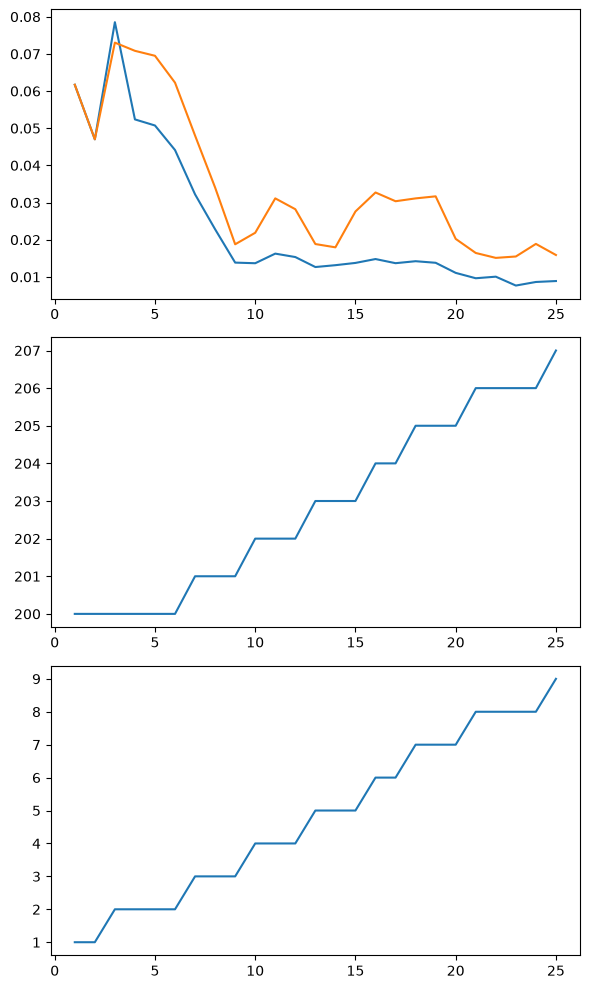

In [214]:
fig, axes = plt.subplots(3, 1, figsize=(6, 10))

x = np.arange(1, epochs + 1)

axes[0].plot(x, mse)
axes[0].plot(x, mse_d)
axes[1].plot(x, active_trees)
axes[2].plot(x, generations)

plt.tight_layout()
plt.show()